# Hybrid Quantum-Classical Term Deposit Campaign Pipeline

This notebook executes and explains the end-to-end 3-stage pipeline:
1. **Stage 1 – Subscription Prediction:** Leakage-free 5-fold Stratified CV on `Stage1_Train` comparing classical baselines (`LogisticRegression`, `RandomForest`, `RBF SVC`) against quantum/hybrid classifiers (`Quantum Kernel LogReg`, `Quantum Kernel SVC`, `Hybrid VQC`), followed by single-pass prediction and deterministic ranking of `Stage1_Test`.
2. **Stage 2 – Constrained Customer Selection:** Exact QUBO/Ising formulation with slack variables (`QuadraticProgramToQubo`), ground-state verification, `CVaR-QAOA` & `CVaR-SamplingVQE`, 10-qubit constrained `XY-Mixer QAOA` + noisy/mitigated `Aer` benchmarks, and exact brute-force comparison.
3. **Stage 3 – Campaign Outcome Simulation:** 6-qubit $R_y(\theta_j)$ state preparation circuit estimating $P(\text{subscribers} \ge 3)$, benchmarked against exact Poisson-Binomial, classical Monte Carlo, noiseless finite-shot `Aer`, noisy `Aer`, and tensor-product readout error mitigation.

In [1]:
import json
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import RESULTS_DIR, FIGURES_DIR
from src.data_loader import load_campaign_data
from src.stage1_predict import run_stage1
from src.stage2_optimize import run_stage2
from src.stage3_simulate import run_stage3
from src.plots import generate_all_plots

data = load_campaign_data()
print(f"Train rows: {len(data['train'])}, positive rate: {data['train']['y_binary'].mean():.2%}")
print(f"Test rows:  {len(data['test'])}")
print(f"Stage2 rows:{len(data['stage2_data'])}")

Train rows: 300, positive rate: 11.67%
Test rows:  100
Stage2 rows:400


## Stage 1: Subscription Prediction & Ranking
All preprocessing (`BankFeatureEngineer`, `SimpleImputer`, `StandardScaler`, `OneHotEncoder`) and quantum angle projection (`PLSRegression` + smooth sigmoid mapping into $(0, \pi)$) are fitted strictly inside each training fold during 5-fold Stratified CV.

In [2]:
stage1_res = run_stage1(data["train"], data["test"])
cv_rows = []
for model_name, stats in stage1_res["cv_summary"].items():
    row = {"model": model_name}
    row.update(stats["oof_metrics"])
    cv_rows.append(row)
cv_df = pd.DataFrame(cv_rows).sort_values("pr_auc", ascending=False)
display(cv_df.round(4))
print("\nTop 10 Stage 1 Test Candidates:")
display(stage1_res["result_df"].head(10).round(4))

,model,roc_auc,pr_auc,precision_at_10,recall_at_10,brier_score,log_loss,ece_5bin
0,Classical_LogReg,0.6527,0.2453,0.5,0.1429,0.1002,0.3584,0.0309
3,Quantum_Kernel_LogReg,0.6075,0.2406,0.4,0.1143,0.0993,0.3484,0.0043
1,Classical_RF,0.6332,0.2325,0.3,0.0857,0.1010,0.3500,0.0151
4,Quantum_Kernel_SVC,0.5577,0.2250,0.6,0.1714,0.1002,0.3497,0.0089
2,Classical_RBF_SVC,0.6083,0.2195,0.6,0.1714,0.0996,0.3472,0.0162
5,Hybrid_VQC,0.5214,0.1687,0.3,0.0857,0.1030,0.3600,0.0017



Top 10 Stage 1 Test Candidates:


,customer_id,predicted_probability,rank,top_10_flag,classical_logreg_probability,classical_rf_probability,classical_rbf_svc_probability,quantum_kernel_svc_probability,hybrid_vqc_probability
0,C0081,0.4331,1,1,0.3700,0.3270,0.5215,0.3150,0.1157
1,C0031,0.4233,2,1,0.5924,0.2992,0.4856,0.3184,0.1156
2,C0079,0.4043,3,1,0.7290,0.2807,0.5154,0.3232,0.1155
3,C0265,0.2435,4,1,0.1374,0.1800,0.0998,0.1103,0.1151
4,C0183,0.2335,5,1,0.2328,0.2327,0.1227,0.1104,0.1140
5,C0359,0.2285,6,1,0.1273,0.1857,0.1046,0.1103,0.1151
6,C0327,0.2200,7,1,0.1980,0.2395,0.1239,0.1103,0.1150
7,C0349,0.2089,8,1,0.1322,0.1863,0.1191,0.1103,0.1150
8,C0206,0.2075,9,1,0.1301,0.1412,0.0984,0.1103,0.1150
9,C0222,0.2038,10,1,0.0946,0.1902,0.1350,0.1103,0.1150


## Stage 2: Constrained Customer Selection ($K=6$, Budget $C \le 25$, Capacity $H \le 22$)
We solve the Stage 2 selection problem using:
- **Full 20-qubit Slack-Variable QUBO** (`QuadraticProgramToQubo` with 10 decision + 10 slack qubits) solved via `CVaR-SamplingVQE` and `CVaR-QAOA`, with exact vectorized verification of the Ising ground state.
- **10-qubit Dicke-State $|D_{10}^6\rangle$ + XY-Mixer QAOA** and hardware-efficient **10-qubit CVaR-VQE** across Ideal, Finite-Shot, Noisy Unmitigated, and Readout-Mitigated regimes.
- **Exact Classical Brute-Force** across all $\binom{10}{6} = 210$ subsets.

In [3]:
stage2_res = run_stage2(stage1_res["result_df"], data["stage2_data"])
print("Primary Quantum Solver:", stage2_res["primary_solver_name"])
print("Selected IDs:", stage2_res["primary_selection"]["selected_ids"])
print(f"Quantum Objective: {stage2_res['primary_selection']['objective_value']:.4f} | "
      f"Exact Objective: {stage2_res['exact_benchmark']['optimal']['objective_value']:.4f} | "
      f"Optimality Gap: {stage2_res['optimality_gap']:.6f}")
print(f"Budget Used: {stage2_res['primary_selection']['budget_total']:.0f}/25 | "
      f"Capacity Used: {stage2_res['primary_selection']['capacity_total']:.0f}/22")
display(stage2_res["result_df"].round(4))

Primary Quantum Solver: QUBO_CVaR_QAOA
Selected IDs: ['C0081', 'C0031', 'C0079', 'C0327', 'C0349', 'C0206']
Quantum Objective: 23.1835 | Exact Objective: 23.1835 | Optimality Gap: 0.000000
Budget Used: 13/25 | Capacity Used: 16/22


,customer_id,rank,predicted_probability,contact_cost,expected_deposit_value,capacity_units,customer_segment,expected_net_value,selected_flag,classical_exact_selected_flag,primary_quantum_solver,selected_budget_total,selected_capacity_total,quantum_objective_value,classical_exact_objective,optimality_gap,best_bitstring_x0_to_x9,top3_qaoa_bitstrings,sampling_vqe_bitstring_x0_to_x9,hw_vqe_10q_bitstring_x0_to_x9
0,C0081,1,0.4331,4,17,1,C,3.3630,1,1,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
1,C0031,2,0.4233,2,13,1,D,3.5023,1,1,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
2,C0079,3,0.4043,3,24,3,A,6.7034,1,1,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
3,C0265,4,0.2435,4,23,4,D,1.5994,0,0,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
4,C0183,5,0.2335,2,14,3,B,1.2687,0,0,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
5,C0359,6,0.2285,1,14,2,D,2.1992,0,0,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
6,C0327,7,0.2200,1,25,4,B,4.5001,1,1,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
7,C0349,8,0.2089,1,17,3,B,2.5507,1,1,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
8,C0206,9,0.2075,2,22,4,A,2.5639,1,1,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110
9,C0222,10,0.2038,2,21,1,D,2.2801,0,0,QUBO_CVaR_QAOA,13.0,16.0,23.1835,23.1835,0.0,1110001110,1110001110;1110001011;1110001101,1110001011,1110001110


## Stage 3: Quantum Campaign Outcome Simulation ($P(\text{subscribers} \ge 3)$)
Each of the 6 selected customers is mapped to one qubit initialized via $R_y(\theta_j)|0\rangle$ with $\theta_j = 2\arcsin(\sqrt{p_j})$.

Qiskit little-endian: bitstring b of length 6 represents |q5 q4 q3 q2 q1 q0>, so qubit j is character index (5 - j).
         ┌────────────┐ ░ ┌─┐               
   q_0: ─┤ Ry(1.4366) ├─░─┤M├───────────────
         ├────────────┤ ░ └╥┘┌─┐            
   q_1: ─┤ Ry(1.4167) ├─░──╫─┤M├────────────
         ├────────────┤ ░  ║ └╥┘┌─┐         
   q_2: ─┤ Ry(1.3782) ├─░──╫──╫─┤M├─────────
        ┌┴────────────┤ ░  ║  ║ └╥┘┌─┐      
   q_3: ┤ Ry(0.97642) ├─░──╫──╫──╫─┤M├──────
        ├─────────────┤ ░  ║  ║  ║ └╥┘┌─┐   
   q_4: ┤ Ry(0.94928) ├─░──╫──╫──╫──╫─┤M├───
        └┬────────────┤ ░  ║  ║  ║  ║ └╥┘┌─┐
   q_5: ─┤ Ry(0.9458) ├─░──╫──╫──╫──╫──╫─┤M├
         └────────────┘ ░  ║  ║  ║  ║  ║ └╥┘
meas: 6/═══════════════════╩══╩══╩══╩══╩══╩═
                           0  1  2  3  4  5 


,customer_id,stage1_rank,qubit_index,bitstring_position_msb0,predicted_probability,ry_theta_rad,shots,marginal_ones_count_shots,marginal_zeros_count_shots,simulated_marginal_p1_shots,...,quantum_estimate_shots,quantum_estimate_noisy_unmitigated,quantum_estimate_noisy_mitigated,exact_probability,monte_carlo_100k_probability,monte_carlo_matched_probability,error_shots_vs_exact,error_noisy_unmit_vs_exact,error_noisy_mit_vs_exact,error_mc_100k_vs_exact
0,C0081,1,0,5,0.4331,1.4366,8192,3518,4674,0.4294,...,0.2794,0.2865,0.2822,0.282,0.2816,0.2775,-0.0026,0.0044,0.0002,-0.0004
1,C0031,2,1,4,0.4233,1.4167,8192,3410,4782,0.4163,...,0.2794,0.2865,0.2822,0.282,0.2816,0.2775,-0.0026,0.0044,0.0002,-0.0004
2,C0079,3,2,3,0.4043,1.3782,8192,3330,4862,0.4065,...,0.2794,0.2865,0.2822,0.282,0.2816,0.2775,-0.0026,0.0044,0.0002,-0.0004
3,C0327,7,3,2,0.2200,0.9764,8192,1857,6335,0.2267,...,0.2794,0.2865,0.2822,0.282,0.2816,0.2775,-0.0026,0.0044,0.0002,-0.0004
4,C0349,8,4,1,0.2089,0.9493,8192,1764,6428,0.2153,...,0.2794,0.2865,0.2822,0.282,0.2816,0.2775,-0.0026,0.0044,0.0002,-0.0004
5,C0206,9,5,0,0.2075,0.9458,8192,1628,6564,0.1987,...,0.2794,0.2865,0.2822,0.282,0.2816,0.2775,-0.0026,0.0044,0.0002,-0.0004


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Figure: stage1_cv_comparison


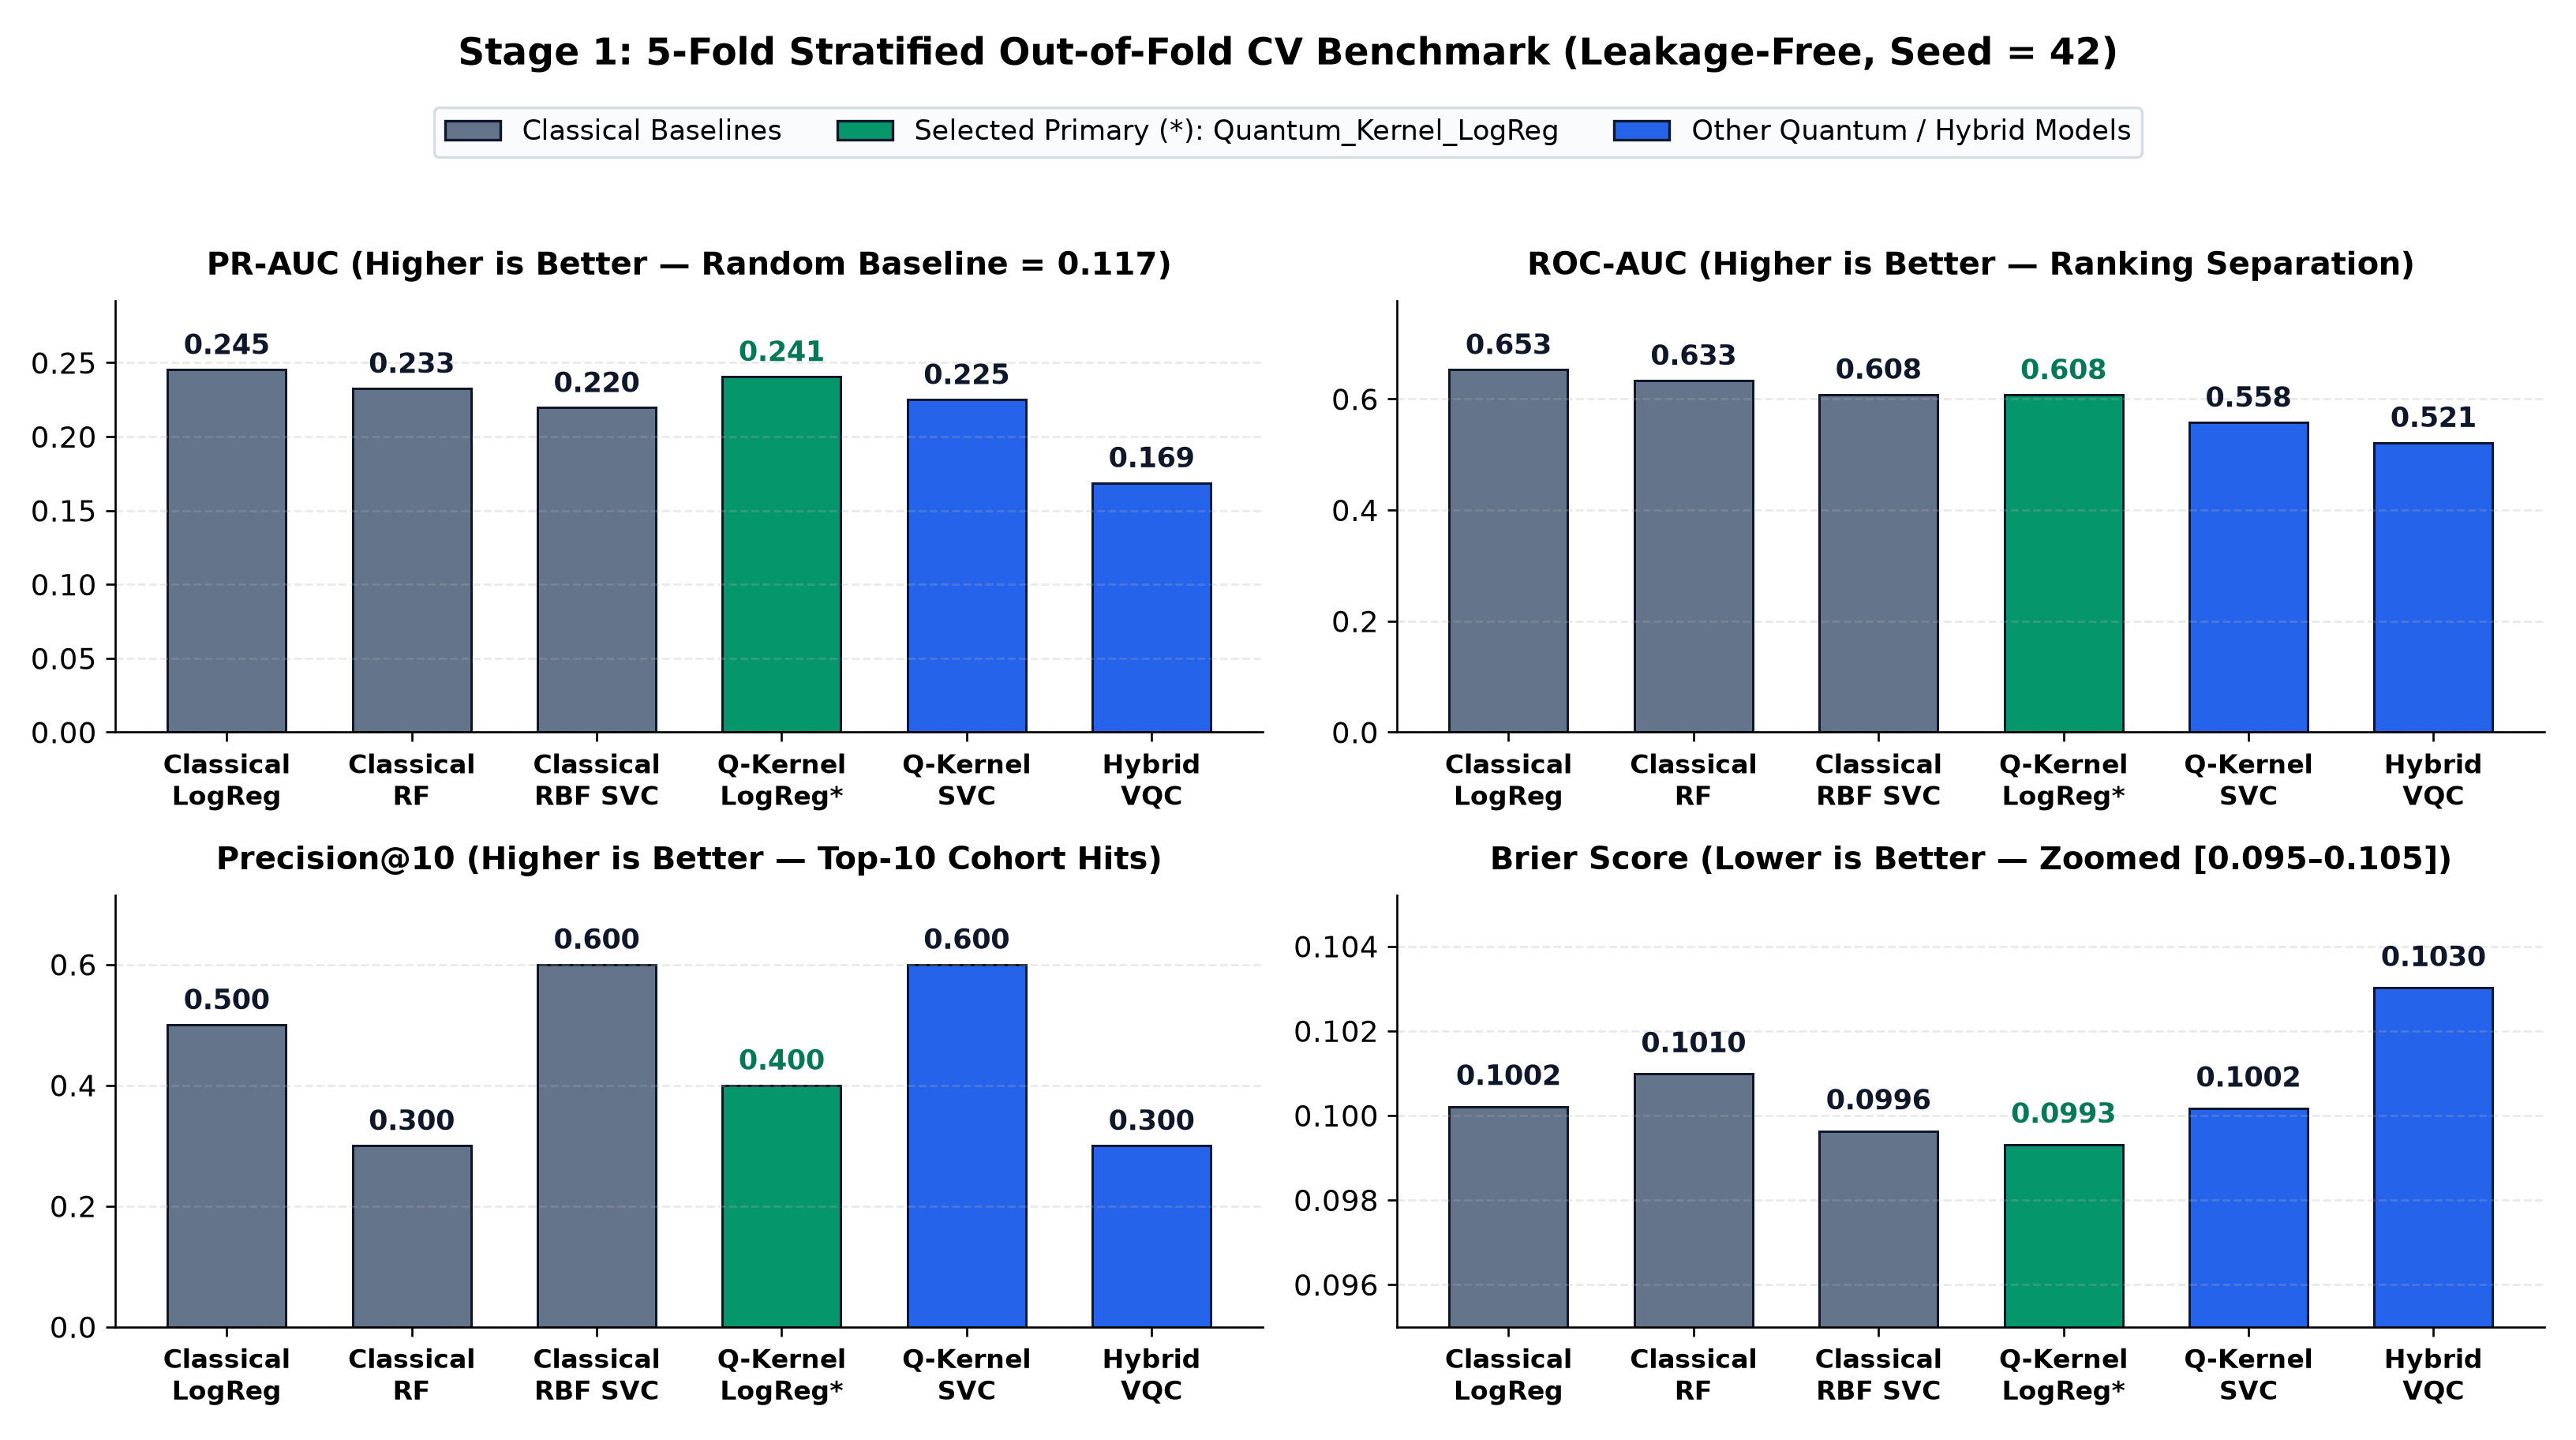

Figure: stage1_calibration_and_top10


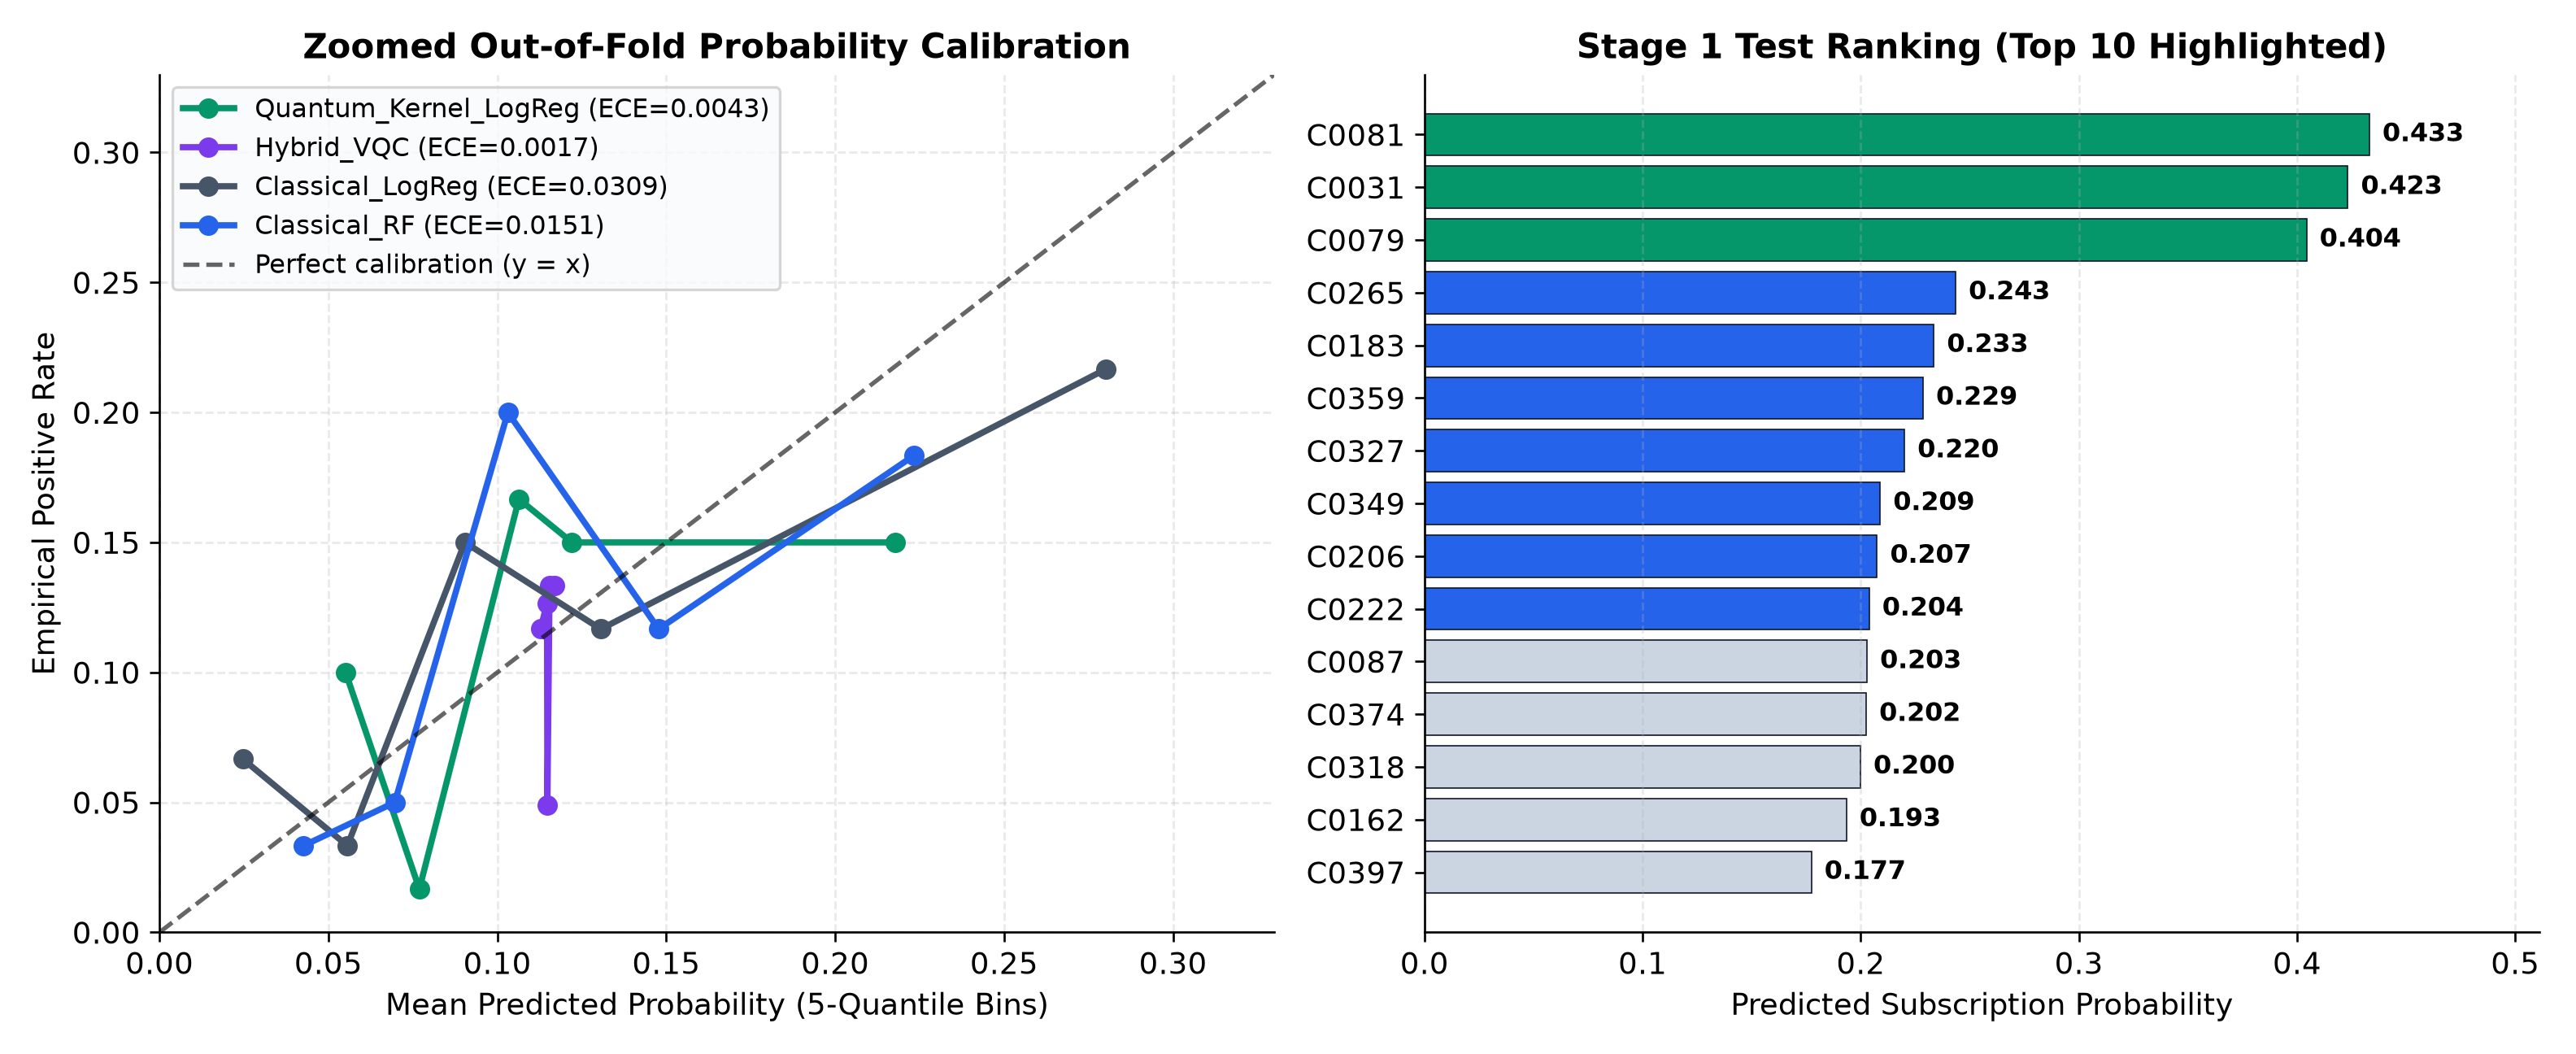

Figure: stage2_optimization_landscape


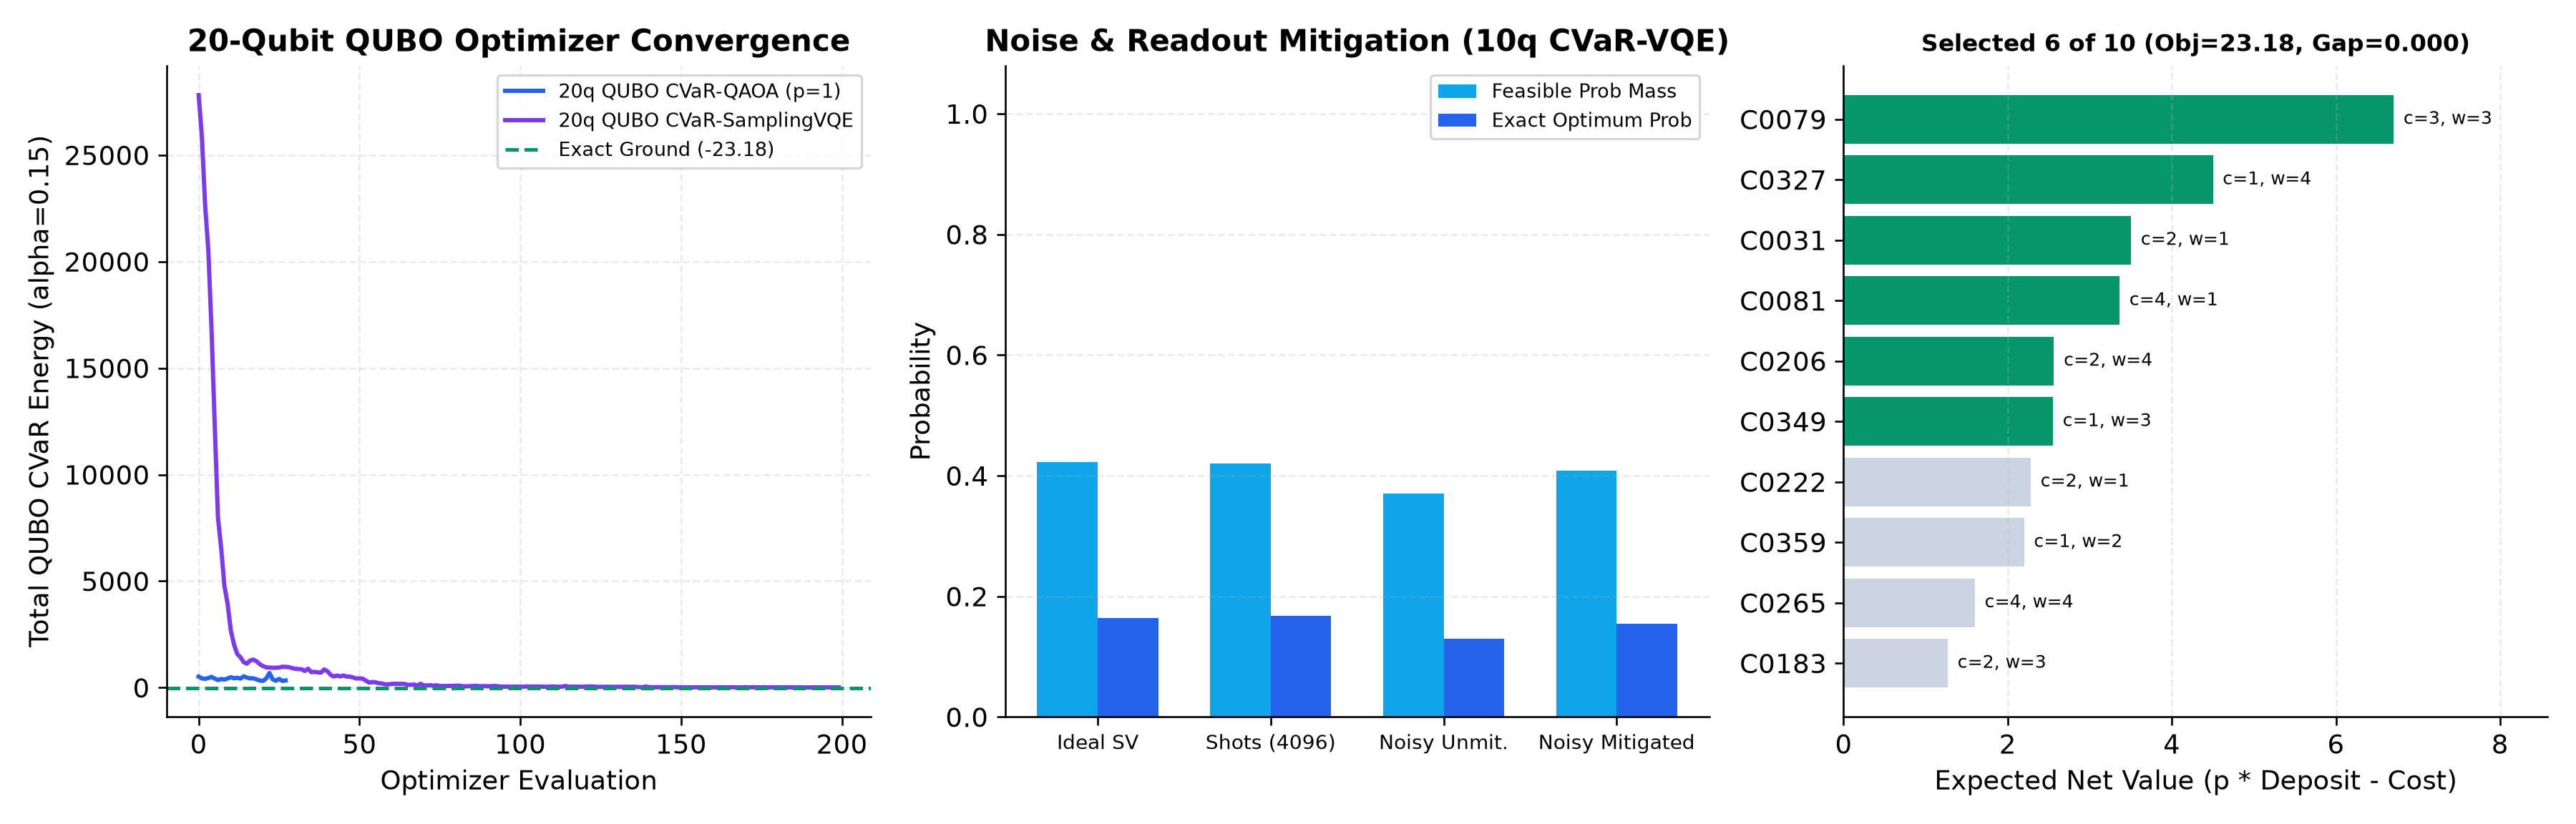

Figure: stage3_circuit_and_outcomes


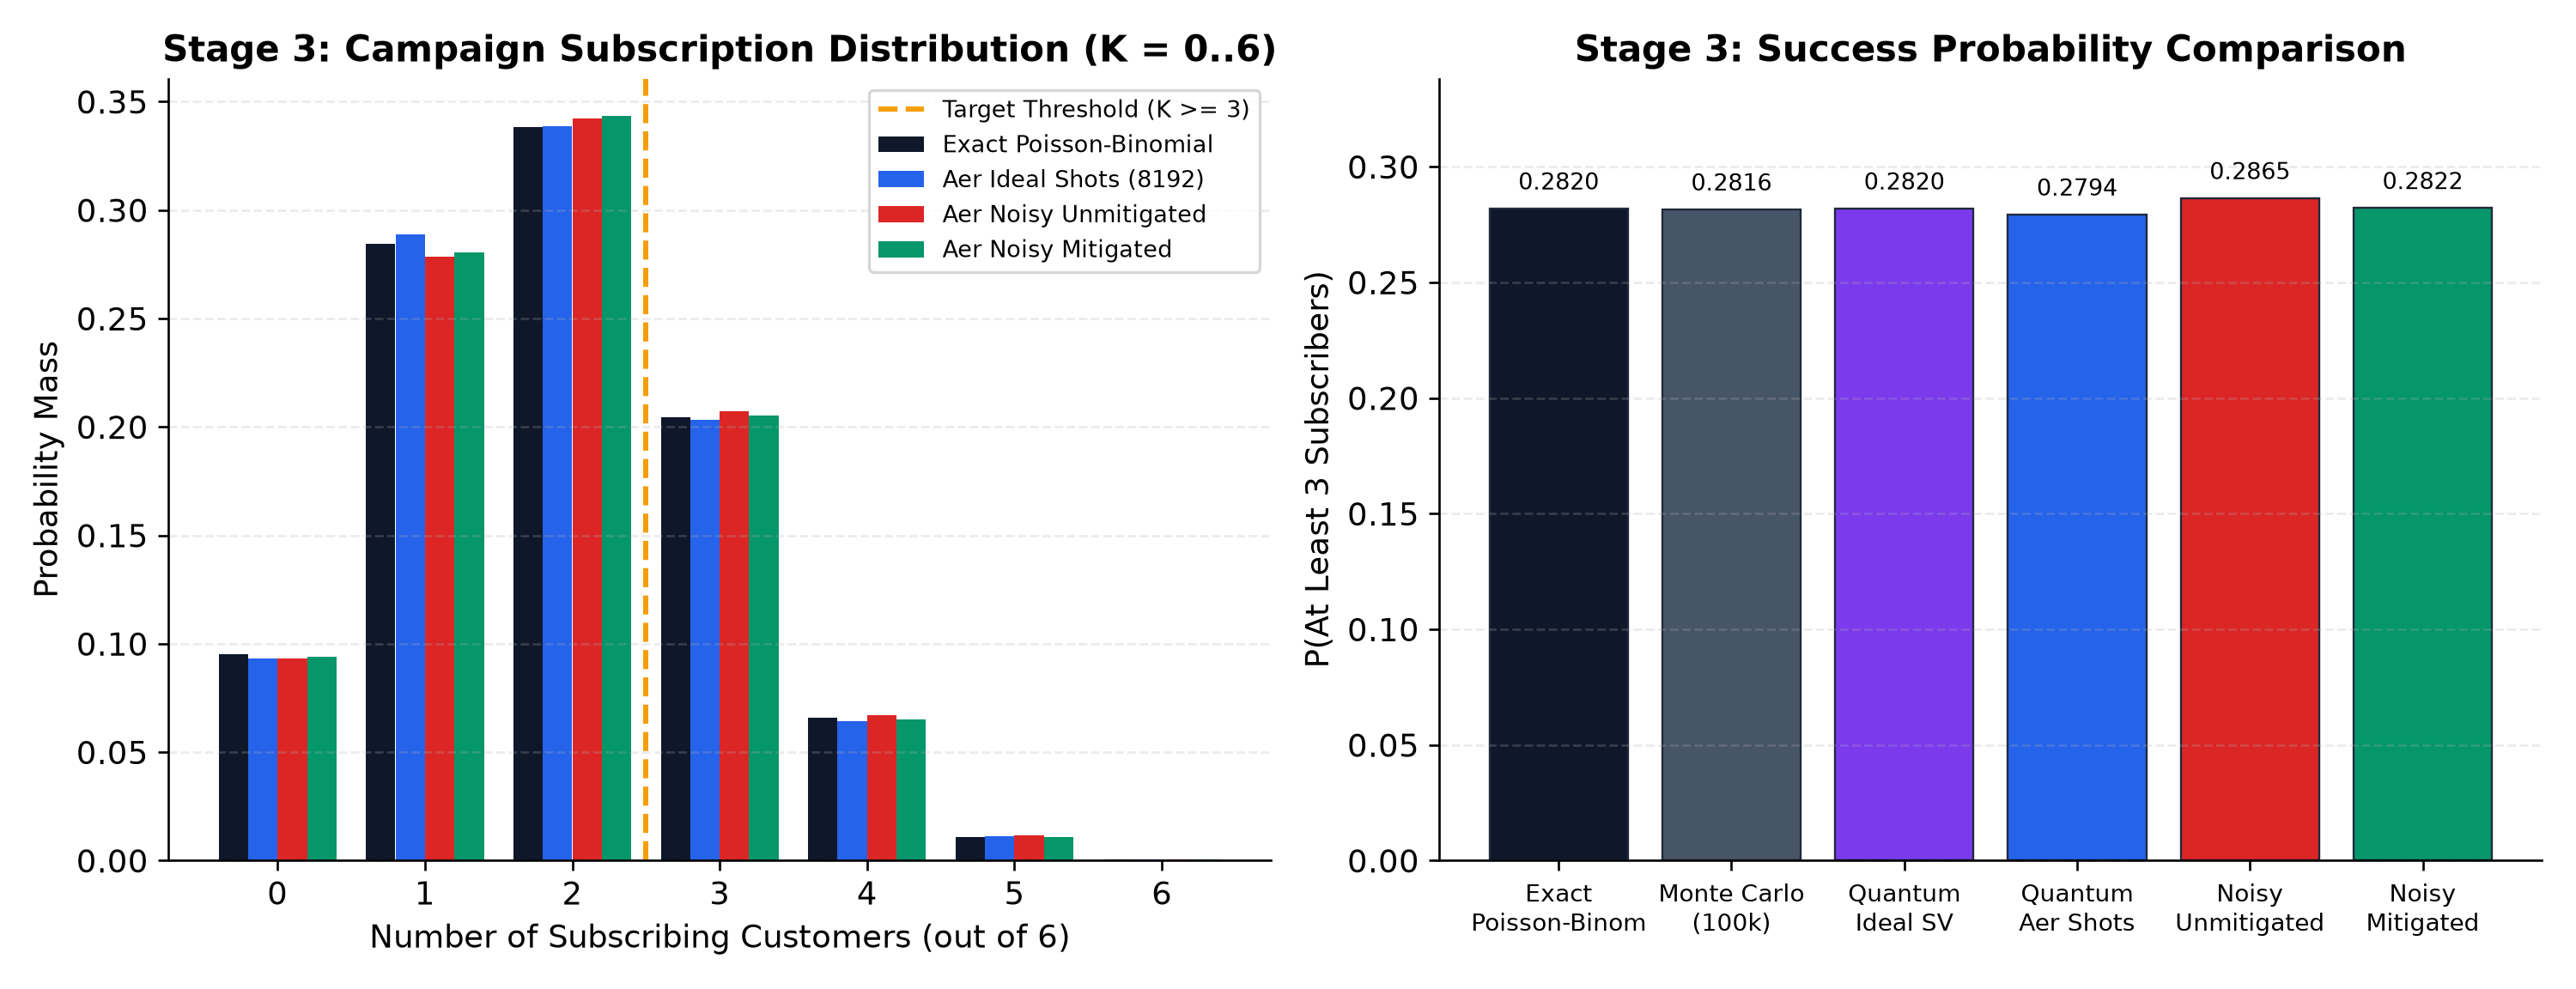

In [4]:
stage3_res = run_stage3(stage2_res["result_df"])
print(stage3_res["bit_ordering_convention"])
print(stage3_res["circuit_qasm_text"])
display(stage3_res["result_df"].round(4))

figs = generate_all_plots(stage1_res, stage2_res, stage3_res)
for label, fig_path in figs.items():
    print(f"Figure: {label}")
    display(Image(filename=fig_path))